In [1]:
# Import dependencies once and set shared parameters.
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
ANALYSIS_YEAR = 2026
VALIDATION_YEAR = 2023
TEST_YEAR = 2024
DATA_FILENAME = 'kaggle_london_house_price_data.csv'
sns.set_theme(style='whitegrid', palette=['#2563a6', '#d48b20', '#64748b'])
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 15)
print('Python:', platform.python_version())

Python: 3.12.14


## 1. Get & understand the data
**Input:** [Jake Wright's London House Price Data on Kaggle](https://www.kaggle.com/datasets/jakewright/house-price-data), supplied as a CSV. **Output:** schema, date coverage and source fingerprint.

The file combines historical sale prices/dates with property characteristics and estimated values. Repeated addresses may represent repeated sales or conflicting records; a row is not automatically a unique property. Hosting on Kaggle alone does not establish reliability: the original collection process and transaction lineage remain unverified. Current attributes may not describe the property at the historical sale date.

In [2]:
# Find the local file, load it and record its identity.
paths = [Path.home()/DATA_FILENAME, Path.cwd()/DATA_FILENAME,
         Path.cwd()/'upload'/DATA_FILENAME, Path.cwd().parent/'upload'/DATA_FILENAME]
data_path = next((p for p in paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f'Place {DATA_FILENAME} beside the notebook or in your home directory.')
df = pd.read_csv(data_path)
source_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
print('File:', data_path)
print('SHA-256:', source_hash)
print('Rows and columns:', df.shape)
print('Sale dates:', df['history_date'].min(), 'to', df['history_date'].max())
print('Unique addresses:', df['fullAddress'].nunique())
display(df[['outcode', 'propertyType', 'floorAreaSqM', 'bedrooms', 'history_date', 'history_price']].head())
df.info()

File: /workspace/scratch/64b4d2620d47/upload/kaggle_london_house_price_data.csv
SHA-256: 9154dc537176031b5d395e2b340513745d1df7dc3368dd9cdea172a028d21522
Rows and columns: (418201, 28)
Sale dates: 1995-01-02 to 2024-09-27
Unique addresses: 137760
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418201 entries, 0 to 418200
Data columns (total 28 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   fullAddress                                418201 non-null  object 
 1   postcode                                   418201 non-null  object 
 2   country                                    418201 non-null  object 
 3   outcode                                    418201 non-null  object 
 4   latitude                                   418201 non-null  float64
 5   longitude                                  418201 non-null  float64
 6   bathrooms                                  340270 non

,outcode,propertyType,floorAreaSqM,bedrooms,history_date,history_price
0,EC4A,Purpose Built Flat,45.0,1.0,1995-01-02,830000
1,EC4A,Flat/Maisonette,NaN,NaN,1995-01-02,830000
2,SW1P,Flat/Maisonette,71.0,2.0,1995-01-03,249950
3,SE5,Flat/Maisonette,64.0,1.0,1995-01-03,32000
4,N10,End Terrace House,137.0,4.0,1995-01-03,133000


**Key takeaway:** recorded sales end in September 2024. The dataset can support historical experiments, but it cannot independently establish 2026 market conditions. The fingerprint makes input differences traceable; earlier uploaded notebook outputs had slightly different duplicate counts.

## 2. Explore & clean the data
**Input:** raw `df`. **Output:** `df_clean` and a cleaning audit.

We preserve the existing project's modelling scope: floor area 20–300 m², price £30,000–£5 million, bedrooms 0–10 and historical price per m² £500–£40,000. These are **scope restrictions**, not proof that excluded records are erroneous. In particular, a fixed historical price-per-m² floor can disproportionately exclude older sales. Quality conclusions apply to this restricted sample.

In [3]:
# Profile missingness, remove exact duplicates and select fields.
display(df.isna().mean().mul(100).round(2).sort_values(ascending=False).rename('Missing (%)').to_frame())
raw_rows = len(df)
exact_duplicates = int(df.duplicated().sum())
df_clean = df.drop_duplicates().copy()
keep_cols = ['fullAddress', 'postcode', 'outcode', 'latitude', 'longitude',
             'propertyType', 'tenure', 'currentEnergyRating', 'floorAreaSqM',
             'bedrooms', 'bathrooms', 'livingRooms', 'history_date', 'history_price']
df_clean = df_clean[keep_cols].copy()
df_clean['history_date'] = pd.to_datetime(df_clean['history_date'], errors='coerce')
df_clean['sale_year'] = df_clean['history_date'].dt.year
print('Exact duplicate rows removed:', exact_duplicates)

Exact duplicate rows removed: 7


,Missing (%)
history_percentageChange,43.09
history_numericChange,43.09
currentEnergyRating,20.21
bathrooms,18.63
livingRooms,14.47
...,...
outcode,0.00
fullAddress,0.00
postcode,0.00
history_price,0.00


In [4]:
# Consolidate overlapping property labels into five groups.
# Map the 19 messy labels onto 5 clean property types
type_map = {
    # Flats
    "Purpose Built Flat": "Flat", "Flat/Maisonette": "Flat", "Converted Flat": "Flat",
    # Terraced (mid, end and unspecified terraces)
    "Mid Terrace House": "Terraced", "End Terrace House": "Terraced",
    "Terrace Property": "Terraced", "Terraced": "Terraced",
    "Mid Terrace Property": "Terraced", "End Terrace Property": "Terraced",
    # Semi-detached
    "Semi-Detached House": "Semi-Detached", "Semi-Detached Property": "Semi-Detached",
    # Detached
    "Detached House": "Detached", "Detached Property": "Detached",
    # Bungalows (all types)
    "Bungalow Property": "Bungalow", "Semi-Detached Bungalow": "Bungalow",
    "Detached Bungalow": "Bungalow", "Mid Terrace Bungalow": "Bungalow",
    "Terraced Bungalow": "Bungalow", "End Terrace Bungalow": "Bungalow",
}

# Replace each old label with its new one (anything not in the dictionary becomes NaN)
df_clean["propertyType"] = df_clean["propertyType"].map(type_map)

# Check the result, including missing values
df_clean["propertyType"].value_counts(dropna=False)

Out[4]: 
propertyType
Flat             259791
Terraced         115293
Semi-Detached     30581
Detached          10123
Bungalow           1270
NaN                1136
Name: count, dtype: int64


In [5]:
# Handle missing categories, retain numeric gaps for training-only imputation.
df_clean['tenure'] = df_clean['tenure'].replace({'Feudal': 'Other', 'Shared': 'Other'})
before_missing = len(df_clean)
df_clean = df_clean.dropna(subset=['floorAreaSqM', 'bedrooms', 'propertyType',
                                 'history_price', 'sale_year', 'outcode']).copy()
for col in ['tenure', 'currentEnergyRating']:
    df_clean[col] = df_clean[col].fillna('Unknown')
after_missing = len(df_clean)
df_clean['price_per_sqm'] = df_clean['history_price'] / df_clean['floorAreaSqM']
df_before = df_clean.copy()
df_clean = df_clean.loc[
    df_clean['floorAreaSqM'].between(20, 300)
    & df_clean['history_price'].between(30_000, 5_000_000)
    & df_clean['bedrooms'].between(0, 10)
    & df_clean['price_per_sqm'].between(500, 40_000)
].reset_index(drop=True)
assert len(df_clean) > 0 and df_clean['history_price'].gt(0).all()
display(pd.DataFrame({'Stage': ['Raw', 'After exact duplicates', 'After required fields', 'After scope filters'],
                      'Rows': [raw_rows, raw_rows-exact_duplicates, after_missing, len(df_clean)]}))
repeated_sale_keys = df_clean.duplicated(['fullAddress', 'history_date', 'history_price']).sum()
print('Repeated address/date/price combinations:', repeated_sale_keys)
print('These are flagged for source investigation, not automatically deleted.')
display(df_clean[['history_price', 'floorAreaSqM', 'bedrooms']].describe().round(2))

Repeated address/date/price combinations: 86334
These are flagged for source investigation, not automatically deleted.


,Stage,Rows
0,Raw,418201
1,After exact duplicates,418194
2,After required fields,361891
3,After scope filters,353413


,history_price,floorAreaSqM,bedrooms
count,353413.00,353413.00,353413.00
mean,531525.64,96.21,2.44
std,517105.10,46.57,1.11
min,30000.00,20.00,1.00
25%,227500.00,63.00,2.00
50%,395000.00,84.00,2.00
75%,635000.00,115.00,3.00
max,5000000.00,300.00,9.00


**Key takeaway:** remaining numeric gaps are imputed inside model pipelines after splitting. `price_per_sqm` is used only for scope checks and exploration, never as a predictor. Conflicting sale records and genuine errors still require verification; no claim is made that all outliers have been corrected.

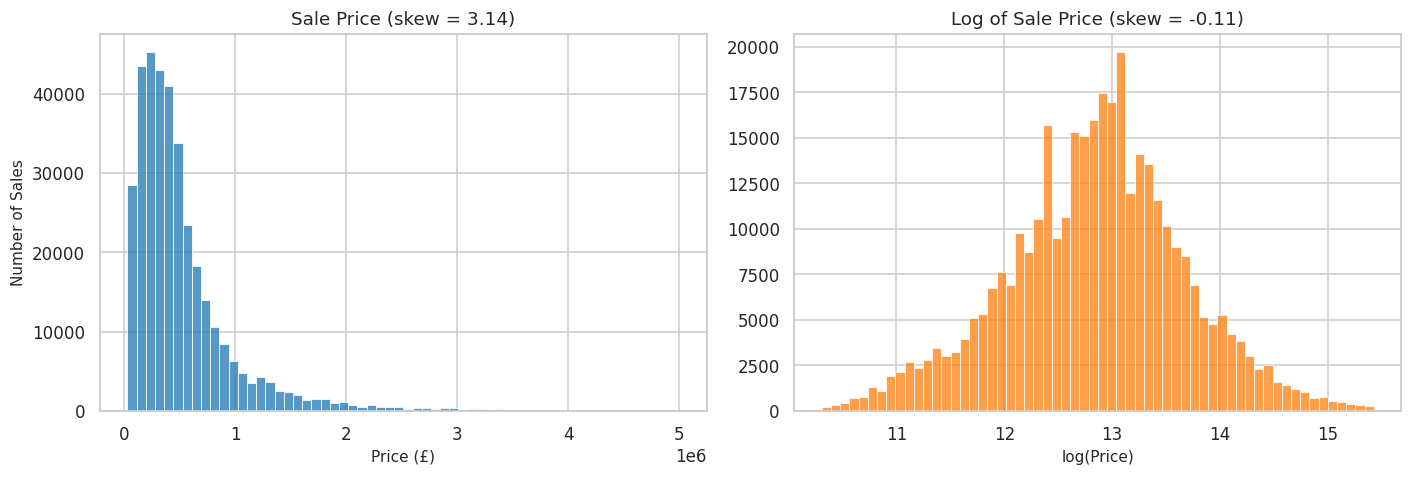

In [6]:
# Compare price distributions before and after taking natural logs.
# Price distribution: raw vs log
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_clean["history_price"], bins=60, ax=axes[0], color="tab:blue")
axes[0].set_title(f"Sale Price (skew = {df_clean['history_price'].skew():.2f})")
axes[0].set_xlabel("Price (£)")
axes[0].set_ylabel("Number of Sales")

sns.histplot(np.log(df_clean["history_price"]), bins=60, ax=axes[1], color="tab:orange")
axes[1].set_title(f"Log of Sale Price (skew = {np.log(df_clean['history_price']).skew():.2f})")
axes[1].set_xlabel("log(Price)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Key takeaway:** log prices are much more symmetric. A normal target is not a linear regression requirement; the log transform changes the relationship and loss being modelled. Normality of residuals is a separate diagnostic.

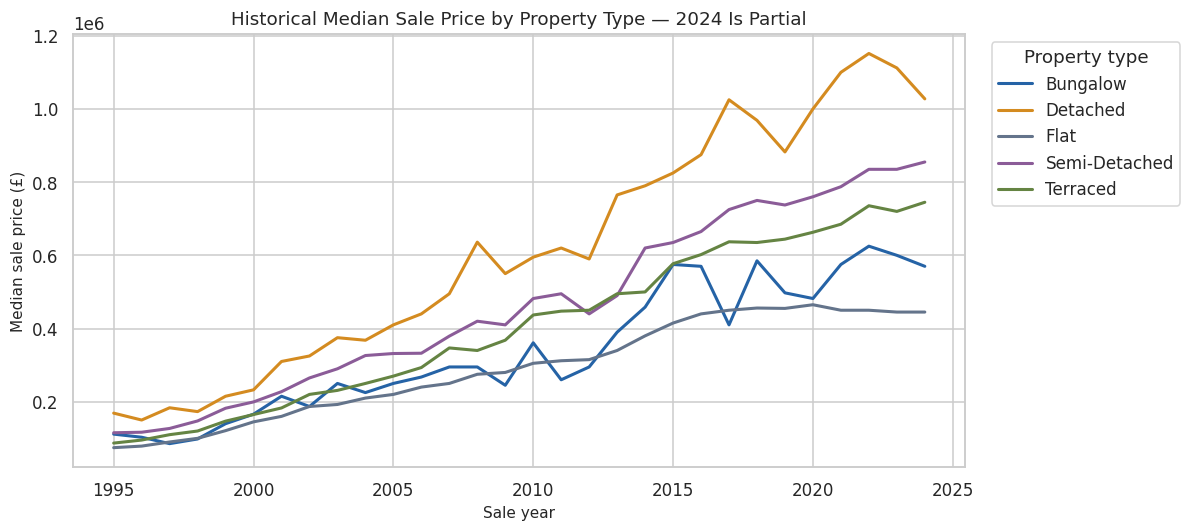

In [7]:
# Compare historical medians with a distinct colour for each property type.
price_by_year = df_clean.groupby(['sale_year','propertyType'])['history_price'].median().unstack()
colours = {'Bungalow':'#2563a6', 'Detached':'#d48b20', 'Flat':'#64748b',
           'Semi-Detached':'#8b5c98', 'Terraced':'#658443'}
ax = price_by_year.plot(figsize=(11,5), linewidth=2,
                        color=[colours[c] for c in price_by_year.columns])
ax.set(title='Historical Median Sale Price by Property Type — 2024 Is Partial',
       xlabel='Sale year', ylabel='Median sale price (£)')
ax.legend(title='Property type', bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout(); plt.show()

In [8]:
# Calculate observed historical changes; label the incomplete year.
yoy = price_by_year.pct_change(fill_method=None).mul(100)
display(yoy.loc[2019:].round(1))
print('2024 covers January–September only; year-to-year medians are composition-sensitive.')

2024 covers January–September only; year-to-year medians are composition-sensitive.


propertyType,Bungalow,Detached,Flat,Semi-Detached,Terraced
sale_year,,,,,
2019,-15.0,-8.9,-0.2,-1.7,1.4
2020,-3.1,13.3,2.2,3.1,2.9
2021,19.3,10.0,-3.2,3.6,3.3
2022,8.7,4.7,0.0,6.0,7.4
2023,-4.0,-3.4,-1.1,0.0,-2.1
2024,-5.0,-7.6,0.0,2.4,3.5


**Key takeaway:** changes in observed median sale prices are historical summaries, not forecasts or constant-quality house-price indices. Both property mix and incomplete-year coverage can influence them.

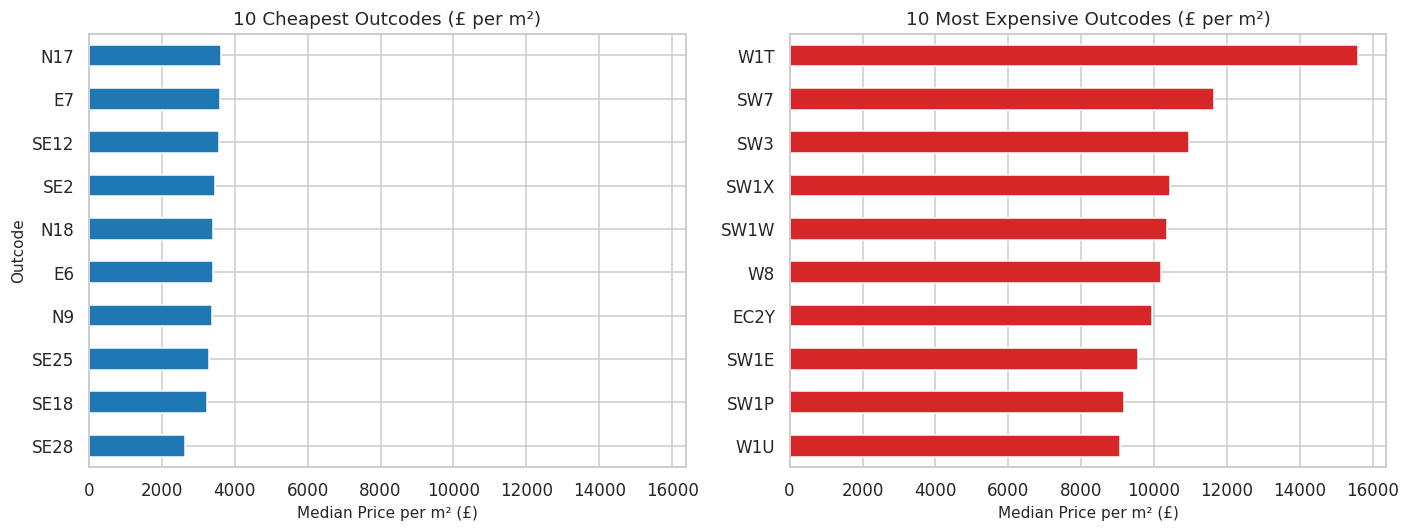

In [9]:
# Compare pooled historical price per m² across sufficiently sampled areas.
# Location: price per m2 by outcode (areas with at least 500 sales)
outcode_stats = (df_clean.groupby("outcode")
                 .agg(sales=("history_price", "size"),
                      median_price=("history_price", "median"),
                      median_ppsqm=("price_per_sqm", "median"))
                 .query("sales >= 500")
                 .sort_values("median_ppsqm"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
outcode_stats.head(10)["median_ppsqm"].plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("10 Cheapest Outcodes (£ per m²)")
axes[0].set_xlabel("Median Price per m² (£)")
axes[0].set_ylabel("Outcode")

outcode_stats.tail(10)["median_ppsqm"].plot(kind="barh", ax=axes[1], color="tab:red")
axes[1].set_title("10 Most Expensive Outcodes (£ per m²)")
axes[1].set_xlabel("Median Price per m² (£)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Key takeaway:** the area charts pool historical years. Price per m² adjusts for size only; it does not control for sale year, condition or property mix, so these are not current area valuations.

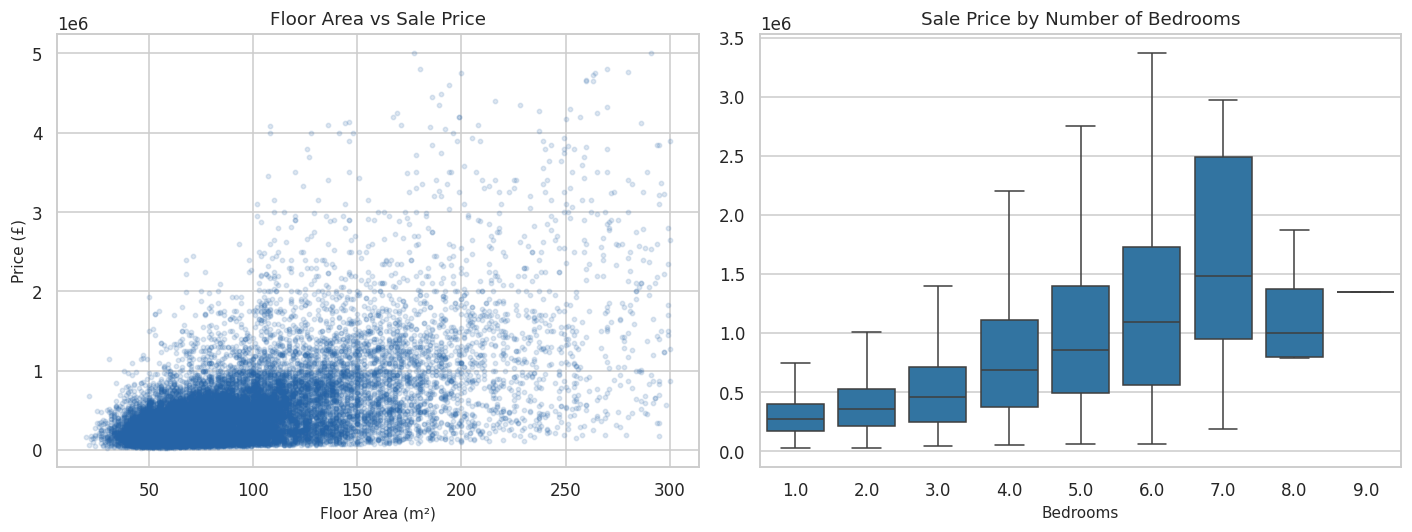

In [10]:
# Explore associations of size and bedrooms with historical price.
# Size and bedrooms vs price (sample of 20,000 sales so the chart is readable)
sample = df_clean.sample(20_000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(sample["floorAreaSqM"], sample["history_price"], alpha=0.15, s=8)
axes[0].set_title("Floor Area vs Sale Price")
axes[0].set_xlabel("Floor Area (m²)")
axes[0].set_ylabel("Price (£)")

sns.boxplot(data=sample, x="bedrooms", y="history_price", ax=axes[1], color="tab:blue", showfliers=False)
axes[1].set_title("Sale Price by Number of Bedrooms")
axes[1].set_xlabel("Bedrooms")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 3. Choose X and y variables
**Input:** cleaned sale records. **Output:** 11 predictors `X`, price target `y`, and address grouping labels.

Numeric features: floor area, bedrooms, bathrooms, living rooms, latitude, longitude and sale year. Categorical features: property type, tenure, energy rating and outcode. Exclude price estimates, derived target changes and price per m² to avoid direct target information. Address is used only to group records, not predict prices.

In [11]:
# Separate predictor columns, sale prices and property groups.
numeric_features = ["floorAreaSqM", "bedrooms", "bathrooms", "livingRooms", "latitude", "longitude", "sale_year"]
categorical_features = ["propertyType", "tenure", "currentEnergyRating", "outcode"]

target = "history_price"
group_col = "fullAddress"   # used ONLY to keep the same property out of both train and test

X = df_clean[numeric_features + categorical_features]
y = df_clean[target]
groups = df_clean[group_col]

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (353413, 11)
y shape: (353413,)
Out[11]: 
   floorAreaSqM  bedrooms  bathrooms  livingRooms   latitude  longitude  \
0          45.0       1.0        1.0          1.0  51.517282  -0.110314   
1          71.0       2.0        2.0          1.0  51.495505  -0.132379   
2          64.0       1.0        1.0          1.0  51.478185  -0.092201   
3         137.0       4.0        1.0          2.0  51.588774  -0.139599   
4          97.0       2.0        1.0          1.0  51.466089   0.006967   

   sale_year propertyType     tenure currentEnergyRating outcode  
0       1995         Flat  Leasehold             Unknown    EC4A  
1       1995         Flat  Leasehold                   C    SW1P  
2       1995         Flat  Leasehold                   D     SE5  
3       1995     Terraced   Freehold                   D     N10  
4       1995     Terraced   Freehold                   D     SE3  


## 4. Check initial regression assumptions
**Input:** selected predictors and log price. **Output:** skewness, associations and multicollinearity checks.

These are exploratory diagnostics. Correlations and one-feature scatterplots do not establish conditional linearity, causality or independence. The grouped split reduces cross-set property dependence but does not remove within-property dependence.

In [12]:
# Measure price skew before and after log transformation.
# 4.1 Normality / skew of the target
skew_raw = stats.skew(y)
skew_log = stats.skew(np.log(y))
print(f"Skew of price:      {skew_raw:.2f}")
print(f"Skew of log(price): {skew_log:.2f}")

Skew of price:      3.14
Skew of log(price): -0.11


In [13]:
# Inspect marginal associations with price and log price.
# 4.2 Linearity: relationship of each numeric feature with price and log(price)
check = df_clean[numeric_features].copy()
check["price"] = y
check["log_price"] = np.log(y)

corr = check.corr()[["price", "log_price"]].drop(["price", "log_price"])
display(corr.sort_values("log_price", ascending=False))

,price,log_price
sale_year,0.415470,0.645569
floorAreaSqM,0.562735,0.500259
bathrooms,0.480390,0.425779
bedrooms,0.385353,0.377883
livingRooms,0.296820,0.258187
latitude,0.029651,0.038168
longitude,-0.245292,-0.254265


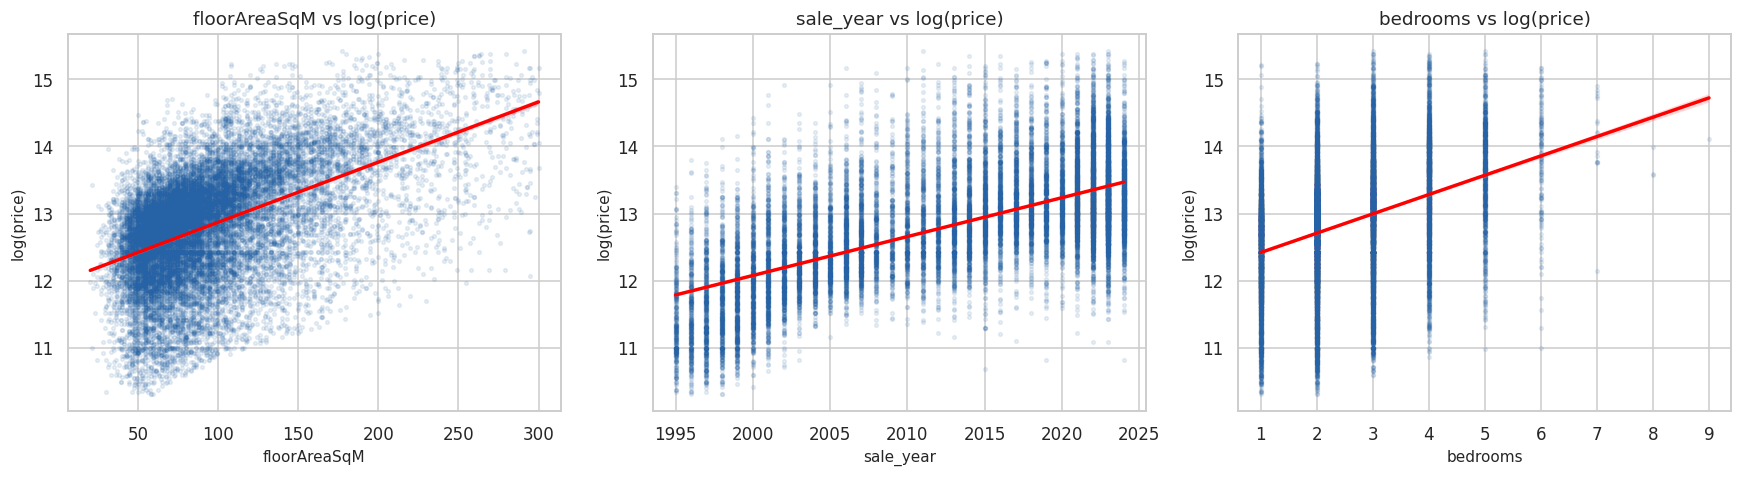

In [14]:
# Plot selected predictors against log price to look for curvature.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sample = check.sample(20_000, random_state=RANDOM_STATE)

for ax, col in zip(axes, ["floorAreaSqM", "sale_year", "bedrooms"]):
    sns.regplot(data=sample, x=col, y="log_price", ax=ax,
                scatter_kws={"alpha": 0.1, "s": 6}, line_kws={"color": "red"})
    ax.set_title(f"{col} vs log(price)")
    ax.set_ylabel("log(price)")

plt.tight_layout()
plt.show()

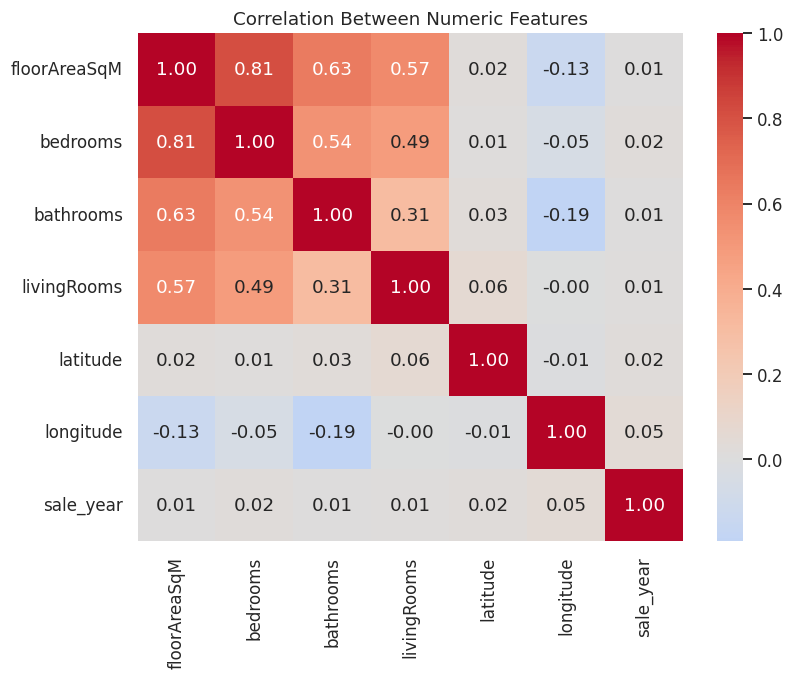

In [15]:
# Inspect correlations among numeric predictors.
# 4.3 Multicollinearity: correlation heatmap between numeric features
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features")
plt.show()

In [16]:
# Calculate numeric-feature VIF as a collinearity diagnostic.
# VIF (Variance Inflation Factor) calculated by hand: VIF = 1 / (1 - R²) when predicting one feature from the others
vif_data = df_clean[numeric_features].dropna().sample(min(50_000, len(df_clean[numeric_features].dropna())), random_state=RANDOM_STATE)

vif_rows = []
for col in numeric_features:
    others = vif_data.drop(columns=col)
    r2 = LinearRegression().fit(others, vif_data[col]).score(others, vif_data[col])
    vif_rows.append({"feature": col, "VIF": 1 / (1 - r2)})

display(pd.DataFrame(vif_rows).sort_values("VIF", ascending=False))

,feature,VIF
0,floorAreaSqM,4.191515
1,bedrooms,3.075684
2,bathrooms,1.725562
3,livingRooms,1.519325
5,longitude,1.057891
4,latitude,1.003917
6,sale_year,1.002373


**Key takeaway:** the executed numeric VIF values range from about 1.00 to 4.19; none exceed the common warning threshold of 5. Larger VIF values warn that individual coefficients may be unstable. They do not automatically invalidate prediction. All one-hot categories are retained for prediction; individual categorical coefficients should not be read as unique effects relative to an omitted baseline. Residual variance and normality are checked after fitting.

## 5. Split into training & test data
**Input:** `X`, `y`, address groups. **Output:** property-grouped training and test sets.

An approximately 80/20 address-grouped split assesses historical prices for held-out properties. It mixes years and does not test forecasting. Later, 2023 validation and 2024 testing address a different question: predicting later sales.

In [17]:
# Split by property address and verify there is no address overlap.
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Training rows: {len(X_train):,} ({len(X_train) / len(X):.0%})")
print(f"Test rows:     {len(X_test):,} ({len(X_test) / len(X):.0%})")

# Safety check: no property should appear in both sets
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print("Properties in both train and test:", len(overlap))

Training rows: 283,086 (80%)
Test rows:     70,327 (20%)
Properties in both train and test: 0


In [18]:
# Inspect price distributions and year coverage in both sets.
# Check the two sets look alike (similar price distribution and year range)
summary = pd.DataFrame({
    "Train": y_train.describe(),
    "Test": y_test.describe(),
})
display(summary)
print("Train years:", X_train["sale_year"].min(), "to", X_train["sale_year"].max())
print("Test years: ", X_test["sale_year"].min(), "to", X_test["sale_year"].max())

Train years: 1995 to 2024
Test years:  1995 to 2024


,Train,Test
count,2.830860e+05,7.032700e+04
mean,5.312244e+05,5.327383e+05
std,5.181906e+05,5.127143e+05
min,3.000000e+04,3.000000e+04
25%,2.270000e+05,2.300000e+05
50%,3.950000e+05,3.950000e+05
75%,6.350000e+05,6.400000e+05
max,5.000000e+06,5.000000e+06


## 6. Create & train the baseline model
**Input:** property-grouped training data. **Output:** fitted `linear_model`.

The pipeline learns median imputation, numeric scaling and categorical encoding from training data only. It predicts log price, then exponentiates to pounds. Exponentiating a predicted log mean does not generally yield the arithmetic mean price; this can contribute to pound-scale bias. No retransformation correction is claimed.

In [19]:
# Define preprocessing, wrap log-price regression, then fit training data.
def build_model(regressor):
    numeric_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                             ('scale', StandardScaler())])
    category_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                              ('encode', OneHotEncoder(handle_unknown='ignore', min_frequency=20))])
    prep = ColumnTransformer([('num', numeric_pipe, numeric_features),
                              ('cat', category_pipe, categorical_features)])
    return TransformedTargetRegressor(
        regressor=Pipeline([('prep', prep), ('model', regressor)]),
        func=np.log, inverse_func=np.exp)

linear_model = build_model(LinearRegression())
linear_model.fit(X_train, y_train)
print('Baseline fitted using training data only.')

Baseline fitted using training data only.


## 7. Make predictions
**Input:** fitted baseline and held-out properties. **Output:** predicted prices in pounds with actual prices for comparison.

In [20]:
# Predict test prices and display a small comparison table.
predicted = linear_model.predict(X_test)
actual = y_test.to_numpy()
results = X_test[['propertyType', 'outcode', 'floorAreaSqM', 'bedrooms', 'sale_year']].copy()
results['Actual (£)'] = actual
results['Predicted (£)'] = predicted
results['Residual (£)'] = actual-predicted
display(results.head(10).round(0))
print('Positive residual = underestimated; negative residual = overestimated.')

Positive residual = underestimated; negative residual = overestimated.


,propertyType,outcode,floorAreaSqM,bedrooms,sale_year,Actual (£),Predicted (£),Residual (£)
15,Semi-Detached,N21,118.0,3.0,1995,152500,129660.0,22840.0
20,Terraced,N17,73.0,2.0,1995,37000,73240.0,-36240.0
27,Flat,W1G,87.0,2.0,1995,170000,242281.0,-72281.0
33,Terraced,SE25,136.0,4.0,1995,86000,111107.0,-25107.0
34,Semi-Detached,W12,98.0,3.0,1995,85000,160477.0,-75477.0
46,Flat,WC1R,71.0,2.0,1995,123000,213925.0,-90925.0
85,Terraced,SE18,115.0,3.0,1995,68000,88652.0,-20652.0
89,Terraced,W7,157.0,5.0,1995,110000,182510.0,-72510.0
90,Semi-Detached,W4,132.0,4.0,1995,127000,222737.0,-95737.0
93,Terraced,N22,97.0,3.0,1995,76000,116618.0,-40618.0


## 8. Evaluate model performance
**Input:** actual and predicted prices. **Output:** MAE, RMSE, R² and median absolute percentage error.

MAE is the mean absolute error in pounds; RMSE gives more weight to large errors. R² is explained variation, not percentage accuracy. Median absolute percentage error is the middle relative error, not a prediction interval.

In [21]:
# Define shared metrics and score the baseline on train and test data.
def evaluate_prices(actual_prices, predicted_prices):
    a, p = np.asarray(actual_prices), np.asarray(predicted_prices)
    assert np.isfinite(p).all() and (p > 0).all()
    return {'MAE (£)': mean_absolute_error(a, p),
            'RMSE (£)': np.sqrt(mean_squared_error(a, p)),
            'R²': r2_score(a, p),
            'Median absolute error (%)': np.median(np.abs(a-p)/a)*100}

baseline_scores = evaluate_prices(actual, predicted)
display(pd.DataFrame([baseline_scores], index=['Linear Regression']).round(3))
train_r2 = r2_score(y_train, linear_model.predict(X_train))
print(f'Training R²: {train_r2:.3f}')
print(f'Log-scale test R²: {r2_score(np.log(actual), np.log(predicted)):.3f}')
display(Markdown(f'**Key takeaway:** held-out-property MAE is **£{baseline_scores["MAE (£)"]:,.0f}**, '
                 f'R² is **{baseline_scores["R²"]:.3f}**, and median absolute percentage error is '
                 f'**{baseline_scores["Median absolute error (%)"]:.2f}%**. '
                 'These describe the restricted historical sample, not a current valuation guarantee.'))

Training R²: 0.753
Log-scale test R²: 0.823


,MAE (£),RMSE (£),R²,Median absolute error (%)
Linear Regression,134715.317,251375.325,0.76,20.266


**Key takeaway:** held-out-property MAE is **£134,715**, R² is **0.760**, and median absolute percentage error is **20.27%**. These describe the restricted historical sample, not a current valuation guarantee.

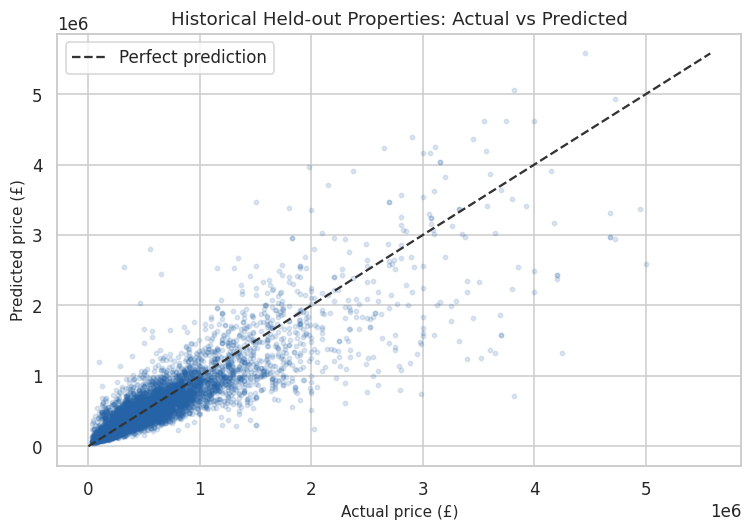

In [22]:
# Compare actual and predicted prices on a readable test sample.
idx = np.random.default_rng(RANDOM_STATE).choice(len(actual), min(10000, len(actual)), replace=False)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(actual[idx], predicted[idx], alpha=.15, s=8)
bound = max(actual[idx].max(), predicted[idx].max())
ax.plot([0, bound], [0, bound], '--', color='#333333', label='Perfect prediction')
ax.set(xlabel='Actual price (£)', ylabel='Predicted price (£)', title='Historical Held-out Properties: Actual vs Predicted')
ax.legend(); plt.tight_layout(); plt.show()

## 9. Analyse residuals & check remaining assumptions
**Input:** held-out-property predictions. **Output:** pound/log residual plots, Q-Q plot and error breakdown.

Residual = actual minus predicted. Positive means underestimation. The log residual plot matches the fitted target scale. A curve suggests missing structure; changing spread suggests non-constant variance. The Q-Q plot checks approximate residual normality, mainly relevant to conventional inference and intervals. A large residual is not proof of high influence; leverage/influence diagnostics remain a limitation.

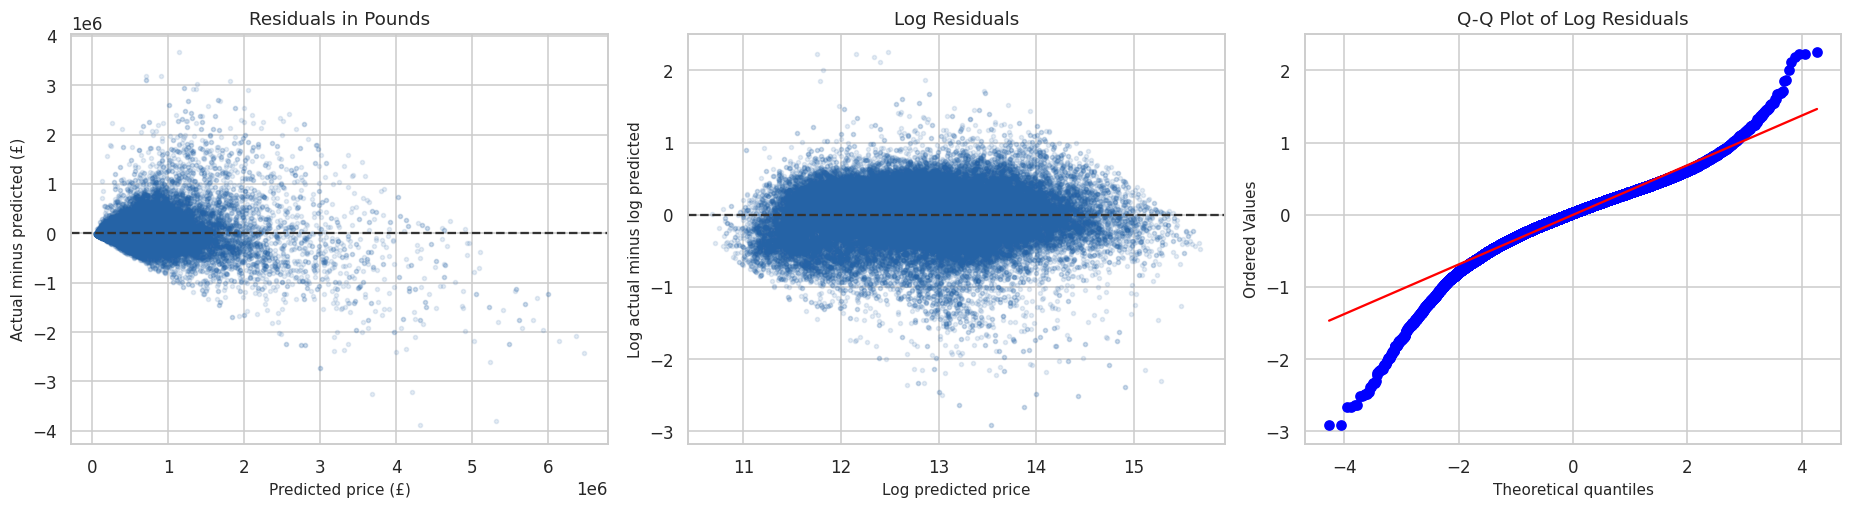

,sales,mean_residual,MAE,median_percentage_error
propertyType,,,,
Bungalow,215,22232.51,89582.97,16.71
Detached,1700,32722.53,224020.69,20.45
Flat,41723,28385.42,123676.52,21.81
Semi-Detached,5411,3575.97,170233.54,18.07
Terraced,21278,22622.25,140649.47,18.03


,mean,std
band,,
"(10.682, 12.175]",-0.030,0.361
"(12.175, 12.691]",0.051,0.322
"(12.691, 13.055]",0.015,0.332
"(13.055, 13.451]",-0.024,0.348
"(13.451, 15.682]",-0.013,0.377


**Key takeaway:** mean pound residual **£24,819** and log residual skewness **-0.757** show remaining bias/asymmetry. The Q-Q tails depart from the line and residual spread is uneven. The price filters shape the residual cloud; neither independence nor constant variance is established.

In [23]:
# Calculate errors, check patterns and normality, and compare property types.
residuals = actual-predicted
log_residuals = np.log(actual)-np.log(predicted)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(predicted, residuals, alpha=.12, s=7)
axes[0].axhline(0, color='#333333', linestyle='--')
axes[0].set(title='Residuals in Pounds', xlabel='Predicted price (£)', ylabel='Actual minus predicted (£)')
axes[1].scatter(np.log(predicted), log_residuals, alpha=.12, s=7)
axes[1].axhline(0, color='#333333', linestyle='--')
axes[1].set(title='Log Residuals', xlabel='Log predicted price', ylabel='Log actual minus log predicted')
stats.probplot(log_residuals, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot of Log Residuals')
plt.tight_layout(); plt.show()
error_results = X_test[['propertyType', 'outcode']].copy()
error_results['residual'] = residuals
error_results['absolute_error'] = np.abs(residuals)
error_results['percentage_error'] = np.abs(residuals)/actual*100
display(error_results.groupby('propertyType').agg(
    sales=('residual', 'size'), mean_residual=('residual', 'mean'),
    MAE=('absolute_error', 'mean'), median_percentage_error=('percentage_error', 'median')).round(2))
bands = pd.qcut(np.log(predicted), 5, duplicates='drop')
display(pd.DataFrame({'band': bands, 'log_residual': log_residuals})
        .groupby('band', observed=True)['log_residual'].agg(['mean', 'std']).round(3))
display(Markdown(f'**Key takeaway:** mean pound residual **£{residuals.mean():,.0f}** '
                 f'and log residual skewness **{stats.skew(log_residuals):.3f}** show remaining bias/asymmetry. '
                 'The Q-Q tails depart from the line and residual spread is uneven. The price filters shape the residual cloud; neither independence nor constant variance is established.'))

## 10. Interpret, improve & retest the model
### 10.1 Test regularisation on the property-grouped split
**Input:** baseline pipeline and training data. **Output:** tuned Ridge and a like-for-like test comparison.

Select alpha from 1, 10 and 100 with three-fold address-grouped training cross-validation and MAE. This is an exploratory experiment: the test has already been inspected, and the sample's target-based filtering affects all scores.

In [24]:
# Tune Ridge on training folds, then compare held-out-property performance.
ridge_candidate = clone(linear_model).set_params(regressor__model=Ridge())
search = GridSearchCV(ridge_candidate, {'regressor__model__alpha': [1,10,100]},
                      scoring='neg_mean_absolute_error', cv=GroupKFold(3), n_jobs=1)
search.fit(X_train, y_train, groups=groups.iloc[train_idx])
best_ridge = search.best_estimator_
ridge_scores = evaluate_prices(y_test, best_ridge.predict(X_test))
print('Selected alpha:', search.best_params_)
print(f'Cross-validation MAE: £{-search.best_score_:,.0f}')
display(pd.DataFrame([baseline_scores, ridge_scores], index=['Linear Regression', 'Tuned Ridge']).round(3))
display(Markdown('**Key takeaway:** Ridge and Linear Regression are very similar on this split. '
                 'Do not claim regularisation improved accuracy unless the displayed errors decrease.'))

Selected alpha: {'regressor__model__alpha': 1}
Cross-validation MAE: £134,788


,MAE (£),RMSE (£),R²,Median absolute error (%)
Linear Regression,134715.317,251375.325,0.760,20.266
Tuned Ridge,134738.770,251445.363,0.759,20.274


**Key takeaway:** Ridge and Linear Regression are very similar on this split. Do not claim regularisation improved accuracy unless the displayed errors decrease.

### 10.2 Validate different historical trends on 2023
**Input:** pre-2023 development data; 2023 validation sales. **Output:** a comparison of the baseline, property-type trends and location trends.

Candidates allow separate year slopes through interactions. Ridge alpha is fixed at 1 for these experiments, following the earlier exploratory work; it is not a freshly tuned temporal optimum. Property-type and location candidates change both features and regularisation, so gains cannot be attributed solely to the interactions. All preprocessing and interaction categories are learned on the development set.

In [25]:
# Define sparse year interactions that learn categories during fitting.
class CategoryTrends(BaseEstimator, TransformerMixin):
    def __init__(self, column='outcode', reference_year=2020):
        self.column = column
        self.reference_year = reference_year

    def fit(self, X, y=None):
        self.encoder_ = OneHotEncoder(handle_unknown='ignore')
        self.encoder_.fit(X[[self.column]])
        return self

    def transform(self, X):
        encoded = self.encoder_.transform(X[[self.column]])
        years = X['sale_year'].to_numpy()-self.reference_year
        return encoded.multiply(years[:, None]).tocsr()

def interaction_model(column):
    prep = FeatureUnion([
        ('original_features', clone(linear_model.regressor_.named_steps['prep'])),
        ('year_interactions', CategoryTrends(column=column))])
    return clone(linear_model).set_params(regressor__prep=prep, regressor__model=Ridge(alpha=1))

# Reproduce the original property-type experiment's scaled numeric interactions.
development = X['sale_year'] < VALIDATION_YEAR
validation = X['sale_year'] == VALIDATION_YEAR
property_types = sorted(X.loc[development, 'propertyType'].unique())
def add_property_trends(data):
    result = data.copy()
    for value in property_types:
        result[f'year_trend_{value}'] = (result['sale_year']-2020)*result['propertyType'].eq(value).astype(int)
    return result
expanded_X = add_property_trends(X)
extra_cols = [col for col in expanded_X if col not in X]
expanded_prep = clone(linear_model.regressor_.named_steps['prep'])
expanded_prep.set_params(transformers=[
    (name, transformer, list(columns)+extra_cols if name=='num' else columns)
    for name, transformer, columns in expanded_prep.transformers])
property_model = clone(linear_model).set_params(regressor__prep=expanded_prep, regressor__model=Ridge(alpha=1))
candidates = {
    'Original Linear Regression': (clone(linear_model), X),
    'Ridge with property-type trends': (property_model, expanded_X),
    'Ridge with location trends': (interaction_model('outcode'), X)}
validation_rows = []
for name, (model, features) in candidates.items():
    model.fit(features.loc[development], y.loc[development])
    validation_rows.append({'Model': name, **evaluate_prices(y.loc[validation], model.predict(features.loc[validation]))})
validation_scores = pd.DataFrame(validation_rows).set_index('Model').sort_values('MAE (£)')
display(validation_scores.round(3))
selected_name = validation_scores.index[0]
print('Selected using 2023 MAE:', selected_name)

Selected using 2023 MAE: Ridge with location trends


,MAE (£),RMSE (£),R²,Median absolute error (%)
Model,,,,
Ridge with location trends,210491.577,339239.732,0.623,24.448
Original Linear Regression,214031.581,334040.788,0.635,25.405
Ridge with property-type trends,217484.946,345726.668,0.609,25.565


**Key takeaway:** use validation MAE, not 2024 results, to select the candidate. This revision rejected property-type trends and preferred location trends: 2023 MAE fell from approximately £214,032 to £210,492, while R² fell from 0.635 to 0.623. This is an absolute-error versus squared-error trade-off. The table above is authoritative for this rerun; earlier saved results differ slightly.

### 10.3 Retest on January–September 2024
**Input:** selected specification and original baseline, refitted on pre-2024 sales. **Output:** later-sale metrics and group errors.

This time split permits the same property to appear in earlier and later periods. It is not a test only of unseen homes. Because 2024 outputs were viewed during development, this is an exploratory retest, not untouched final evidence.

In [26]:
# Refit the baseline and selected candidate before 2024; compare later-sale errors.
earlier = X['sale_year'] < TEST_YEAR
later = X['sale_year'] == TEST_YEAR
selected_template, selected_features = candidates[selected_name]
time_models = {'Original Linear Regression': clone(linear_model)}
if selected_name != 'Original Linear Regression':
    time_models[selected_name] = clone(selected_template)
time_rows = []
time_predictions = {}
for name, model in time_models.items():
    features = selected_features if name == selected_name else X
    model.fit(features.loc[earlier], y.loc[earlier])
    p = model.predict(features.loc[later])
    time_predictions[name] = p
    time_rows.append({'Model': name, **evaluate_prices(y.loc[later], p)})
time_comparison = pd.DataFrame(time_rows).set_index('Model')
selected_time_model = time_models[selected_name]
selected_predictions = time_predictions[selected_name]
display(time_comparison.round(3))
print('2024 test sales:', int(later.sum()))
print('Test dates:', df_clean.loc[later, 'history_date'].min().date(), 'to', df_clean.loc[later, 'history_date'].max().date())
print('Properties in both periods:', len(set(groups.loc[earlier]) & set(groups.loc[later])))
baseline_time = time_comparison.loc['Original Linear Regression']
selected_time = time_comparison.loc[selected_name]
improvement = baseline_time['MAE (£)']-selected_time['MAE (£)']
display(Markdown(f'**Result and decision:** **{selected_name}** was selected on 2023 validation MAE. '
    f'On the 2024 retest its MAE is **£{selected_time["MAE (£)"]:,.0f}**, '
    f'RMSE **£{selected_time["RMSE (£)"]:,.0f}**, R² **{selected_time["R²"]:.3f}**, '
    f'and median absolute percentage error **{selected_time["Median absolute error (%)"]:.2f}%**. '
    f'MAE improvement over the baseline is **£{improvement:,.0f} ({improvement/baseline_time["MAE (£)"]*100:.1f}%)**. '
    'It is the preferred experimental later-sale candidate, not a validated current-market forecast.'))
time_results = X.loc[later, ['propertyType', 'outcode']].copy()
time_results['absolute_error'] = np.abs(y.loc[later].to_numpy()-selected_predictions)
time_results['percentage_error'] = time_results['absolute_error'].to_numpy()/y.loc[later].to_numpy()*100
for group in ['propertyType','outcode']:
    table = time_results.groupby(group).agg(sales=('absolute_error','size'), MAE=('absolute_error','mean'),
                                           median_percentage_error=('percentage_error','median'))
    if group=='outcode': table=table.query('sales >= 100').sort_values('MAE',ascending=False).head(10)
    print('Selected-model errors by', group)
    display(table.round(2))

2024 test sales: 21882
Test dates: 2024-01-02 to 2024-09-27
Properties in both periods: 12404
Selected-model errors by propertyType
Selected-model errors by outcode


,MAE (£),RMSE (£),R²,Median absolute error (%)
Model,,,,
Original Linear Regression,197636.723,300997.336,0.675,24.448
Ridge with location trends,188220.701,293395.671,0.691,22.640


**Result and decision:** **Ridge with location trends** was selected on 2023 validation MAE. On the 2024 retest its MAE is **£188,221**, RMSE **£293,396**, R² **0.691**, and median absolute percentage error **22.64%**. MAE improvement over the baseline is **£9,416 (4.8%)**. It is the preferred experimental later-sale candidate, not a validated current-market forecast.

,sales,MAE,median_percentage_error
propertyType,,,
Bungalow,102,186382.60,26.59
Detached,563,326036.98,17.65
Flat,13033,168888.44,27.92
Semi-Detached,1750,250548.61,17.38
Terraced,6434,198397.94,16.81


,sales,MAE,median_percentage_error
outcode,,,
NW3,123,396338.02,28.22
SW6,226,369171.48,25.95
NW8,177,356324.39,26.76
W2,240,335530.54,30.51
NW1,122,329182.22,41.34
SW13,150,314302.56,22.32
NW6,149,311344.56,36.67
N10,114,305564.95,23.66
NW11,102,281836.36,23.90


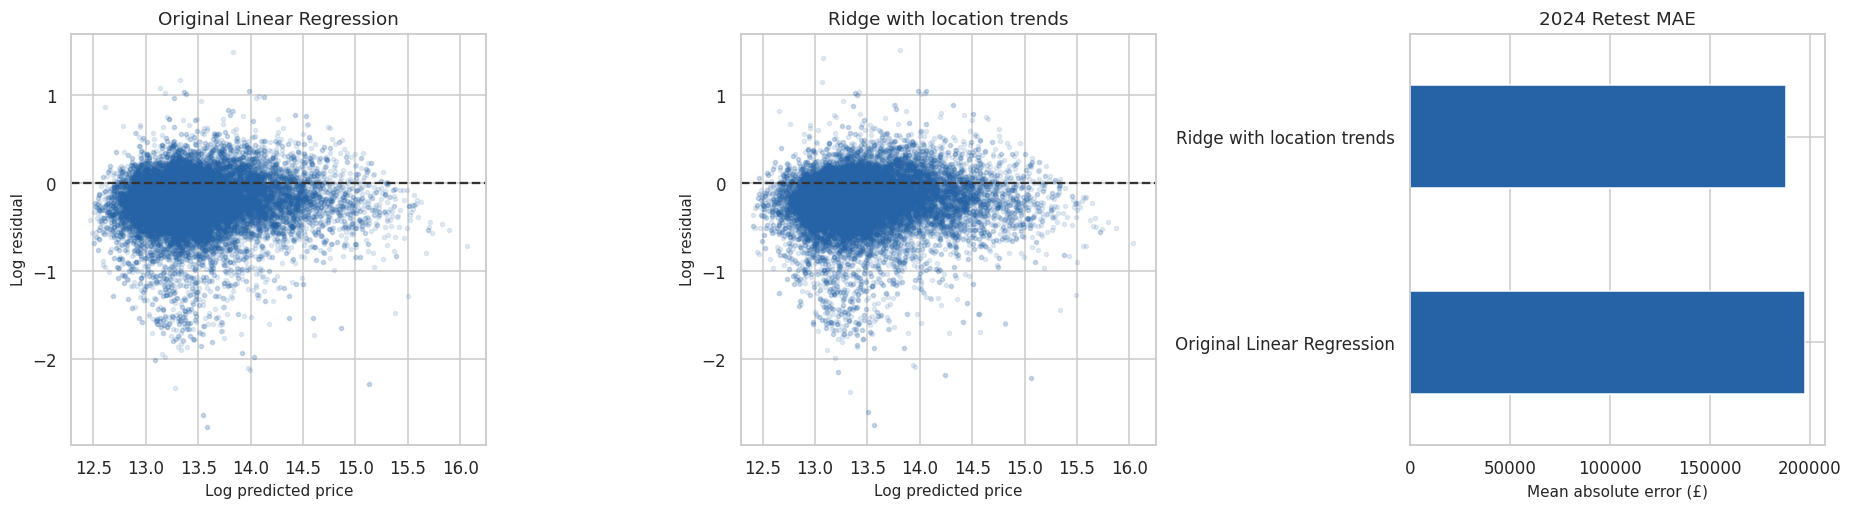

In [27]:
# Compare later-sale error patterns and model MAE using matching scales.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, name in zip(axes[:2], ['Original Linear Regression', selected_name]):
    p = time_predictions[name]
    ax.scatter(np.log(p), np.log(y.loc[later].to_numpy())-np.log(p), s=7, alpha=.12)
    ax.axhline(0, color='#333333', linestyle='--')
    ax.set(title=name, xlabel='Log predicted price', ylabel='Log residual')
axes[1].set_xlim(axes[0].get_xlim()); axes[1].set_ylim(axes[0].get_ylim())
time_comparison['MAE (£)'].plot.barh(ax=axes[2], color='#2563a6')
axes[2].set(title='2024 Retest MAE', xlabel='Mean absolute error (£)', ylabel='')
plt.tight_layout(); plt.show()

### 10.4 Produce labelled next-year scenarios and an example price
**Input:** the selected specification, refitted on all cleaned data through September 2024; fixed profiles from each property's latest available 2024 sale. **Output:** conditional price scenarios grouped by property type and outcode, plus one example profile.

Two horizons are shown: **2024→2025**, anchored to the end of the source data, and **2026→2027**, the brief's current calendar horizon. The latter extrapolates further beyond observed sales and has no contemporary market evidence. Neither horizon is a validated market forecast. Only sale year changes; property characteristics and group composition remain fixed. Duplicated addresses contribute one profile. This profile cohort is not representative of London's housing stock.

**Uncertainty:** no calibrated prediction intervals are available. The 2024 MAE and percentage errors describe past test performance, not bounds around these projections. Growth estimates assume stable historical slopes and omit future rates, supply and economic shocks.

In [28]:
# Refit the chosen specification, hold profiles fixed and change only sale year.
projection_model = clone(selected_template)
projection_model.fit(selected_features, y)
latest_profiles = (df_clean.loc[later].sort_values('history_date')
                   .drop_duplicates('fullAddress', keep='last'))
profile_X = latest_profiles[X.columns].copy()
def features_for_year(profiles, year):
    features = profiles.copy()
    features['sale_year'] = year
    if selected_name == 'Ridge with property-type trends':
        features = add_property_trends(features)
    return features

scenario_tables = {}
for start_year in [TEST_YEAR, ANALYSIS_YEAR]:
    end_year = start_year+1
    first = projection_model.predict(features_for_year(profile_X, start_year))
    second = projection_model.predict(features_for_year(profile_X, end_year))
    scenario = latest_profiles[['propertyType','outcode']].copy()
    scenario['start_price'] = first
    scenario['next_price'] = second
    for group in ['propertyType','outcode']:
        table = scenario.groupby(group).agg(
            profiles=('start_price','size'), start_median=('start_price','median'),
            next_median=('next_price','median'))
        table['change_£'] = table['next_median']-table['start_median']
        table['change_%'] = (table['next_median']/table['start_median']-1)*100
        if group=='outcode': table = table.query('profiles >= 100')
        scenario_tables[(start_year,group)] = table
        print(f'UNVALIDATED SCENARIO {start_year} to {end_year}: by {group}')
        display(table.sort_values('change_%',ascending=False).head(10).round(2))

# Show one existing profile: a worked estimate, not a new observed sale.
example = profile_X.iloc[[0]].copy()
example_price = projection_model.predict(features_for_year(example, ANALYSIS_YEAR+1))[0]
display(example[['propertyType','outcode','floorAreaSqM','bedrooms','bathrooms']])
print(f'Illustrative {ANALYSIS_YEAR+1} scenario estimate for this profile: £{example_price:,.0f}')

UNVALIDATED SCENARIO 2024 to 2025: by propertyType
UNVALIDATED SCENARIO 2024 to 2025: by outcode
UNVALIDATED SCENARIO 2026 to 2027: by propertyType
UNVALIDATED SCENARIO 2026 to 2027: by outcode
Illustrative 2027 scenario estimate for this profile: £763,685


,profiles,start_median,next_median,change_£,change_%
propertyType,,,,,
Bungalow,70,678236.71,724504.43,46267.72,6.82
Detached,403,1158334.96,1235604.33,77269.37,6.67
Terraced,4412,787984.27,840357.96,52373.69,6.65
Semi-Detached,1245,920949.99,980454.81,59504.81,6.46
Flat,8955,549668.32,583493.77,33825.45,6.15


,profiles,start_median,next_median,change_£,change_%
outcode,,,,,
E17,425,618193.48,664825.75,46632.27,7.54
SE4,101,679669.94,730719.46,51049.52,7.51
N16,164,675492.41,724490.54,48998.13,7.25
E8,114,740332.10,793962.01,53629.92,7.24
E10,154,525085.09,562476.10,37391.01,7.12
E11,178,661557.54,708367.77,46810.23,7.08
SE23,153,546343.08,584441.63,38098.55,6.97
N17,143,528234.67,564725.99,36491.33,6.91
N4,157,612370.09,654191.14,41821.05,6.83


,profiles,start_median,next_median,change_£,change_%
propertyType,,,,,
Bungalow,70,773166.79,823701.91,50535.12,6.54
Terraced,4412,894955.50,950561.10,55605.61,6.21
Semi-Detached,1245,1039873.15,1103307.78,63434.63,6.10
Flat,8955,618818.63,655689.36,36870.72,5.96
Detached,403,1317859.38,1395119.93,77260.56,5.86


,profiles,start_median,next_median,change_£,change_%
outcode,,,,,
E17,425,714975.64,768908.49,53932.85,7.54
SE4,101,785603.27,844609.36,59006.09,7.51
N16,164,777042.83,833407.11,56364.28,7.25
E8,114,851476.90,913158.18,61681.29,7.24
E10,154,602529.71,645435.51,42905.80,7.12
E11,178,758490.19,812159.15,53668.96,7.08
SE23,153,625196.94,668794.27,43597.33,6.97
N17,143,603738.20,645445.44,41707.24,6.91
N4,157,698868.30,746596.63,47728.33,6.83


,propertyType,outcode,floorAreaSqM,bedrooms,bathrooms
331548,Flat,N6,55.0,2.0,1.0


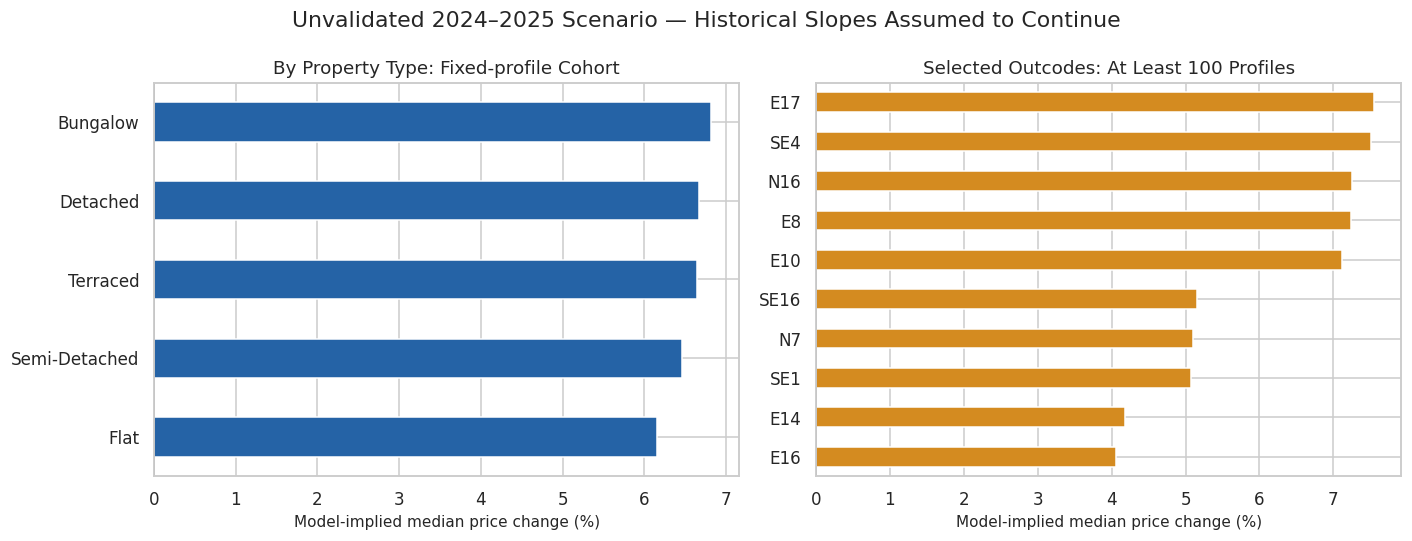

In [29]:
# Visualise the data-anchored scenario and label its unvalidated status.
type_scenario = scenario_tables[(TEST_YEAR,'propertyType')]
area_scenario = scenario_tables[(TEST_YEAR,'outcode')].sort_values('change_%')
area_display = pd.concat([area_scenario.head(5), area_scenario.tail(5)]).loc[lambda d: ~d.index.duplicated()]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
type_scenario['change_%'].sort_values().plot.barh(ax=axes[0], color='#2563a6')
area_display['change_%'].plot.barh(ax=axes[1], color='#d48b20')
axes[0].set(title='By Property Type: Fixed-profile Cohort', ylabel='')
axes[1].set(title='Selected Outcodes: At Least 100 Profiles', ylabel='')
for ax in axes:
    ax.axvline(0,color='#333333',linewidth=1)
    ax.set_xlabel('Model-implied median price change (%)')
fig.suptitle('Unvalidated 2024–2025 Scenario — Historical Slopes Assumed to Continue')
plt.tight_layout(); plt.show()

**Key takeaway:** the location-trend model gives each outcode its own annual percentage slope. Property-type scenario differences arise through the location mix and median aggregation, not separately estimated property-type growth slopes. With the original baseline, all fixed profiles share one annual percentage trend. These tables make the model's assumptions visible; they do not establish actual future market movements.

### Final conclusions — historical estimation versus forecasting

**Historical price prediction.** The model uses size, rooms, location, property type, tenure, energy rating and sale year. The property-grouped baseline explains about 76% of held-out historical price variation, with MAE about £134,715 and median absolute percentage error about 20.27%. It is useful as an interpretable baseline, not a precise valuation.

**Later-sale prediction and model improvement.** Ridge alone did not materially improve the grouped baseline. Property-type trends worsened 2023 validation MAE. Location trends improved validation MAE, despite a small R² decline, and were selected using the predefined MAE criterion. In this executed revision, refitting through 2023 and testing January–September 2024 reduced MAE from £197,637 to £188,221 (4.8%), lowered RMSE to £293,396, increased R² to 0.691 and reduced median absolute percentage error to 22.64%. These reproduce the substantive result of the submitted run (MAE £188,217); small differences reflect the exact supplied CSV and numerical environment. This rerun removes 7 exact duplicate rows and retains 353,413 records, compared with 4 duplicates and 353,415 records in the older saved outputs.

**Forecasting.** The chosen candidate supports explicitly conditional next-year scenarios by location and property type, holding profiles fixed. These extrapolations assume historical trends continue. Because sales end in September 2024, neither the data-anchored 2024–2025 scenario nor the more distant 2026–2027 scenario is a reliable current-market forecast. No calibrated intervals are available. More recent verified transactions and rolling time validation are needed before relying on these projections.

**Remaining limitations.** 2024 was inspected during experimentation; the retest is exploratory. Same-property overlap is allowed across time periods. Current attributes may not match historical attributes. Missing condition, renovation, garden, parking and macroeconomic data limit explanatory power. Target-based scope filters exclude luxury and some older/low-value sales. Conflicting sale keys, source reliability and influential-observation diagnostics remain unresolved. Numeric VIF and residual plots diagnose problems; they do not certify all assumptions.

**Method decision.** Retain the location-trend Ridge candidate for further later-sale work if the rerun again selects it on 2023 MAE. Prioritise source verification, recent data, sensitivity to scope filters and a fresh chronological holdout over adding complexity without validation.